In [1]:
import os, glob, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, precision_recall_curve,
    auc, brier_score_loss
)
from sklearn.calibration import calibration_curve
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
print("Imports OK")

Imports OK


In [2]:
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = "/content/drive/MyDrive/Epileptic Seizure Recognition.csv"
df = pd.read_csv(DATA_PATH)

print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("\nOriginal label counts:")
print(df['y'].value_counts().sort_index())

Mounted at /content/drive
Loaded: /content/drive/MyDrive/Epileptic Seizure Recognition.csv
Shape: (11500, 180)
Missing values: 0

Original label counts:
y
1    2300
2    2300
3    2300
4    2300
5    2300
Name: count, dtype: int64


In [3]:
id_col = df.columns[0]
df['recording_id'] = df[id_col].astype(str).str.split('.', n=1).str[1]

print("ID column used:", id_col)
print("Unique recordings:", df['recording_id'].nunique())
print("Rows per recording:")
print(df.groupby('recording_id').size().value_counts())
print("Labels per recording:")
print(df.groupby('recording_id')['y'].nunique().value_counts())

ID column used: Unnamed
Unique recordings: 500
Rows per recording:
23    500
Name: count, dtype: int64
Labels per recording:
y
1    500
Name: count, dtype: int64


In [4]:
df['seizure'] = (df['y'] == 1).astype(int)

print("Seizure rows:", df['seizure'].sum())
print("Seizure percentage: {:.2f}%".format(df['seizure'].mean() * 100))

Seizure rows: 2300
Seizure percentage: 20.00%


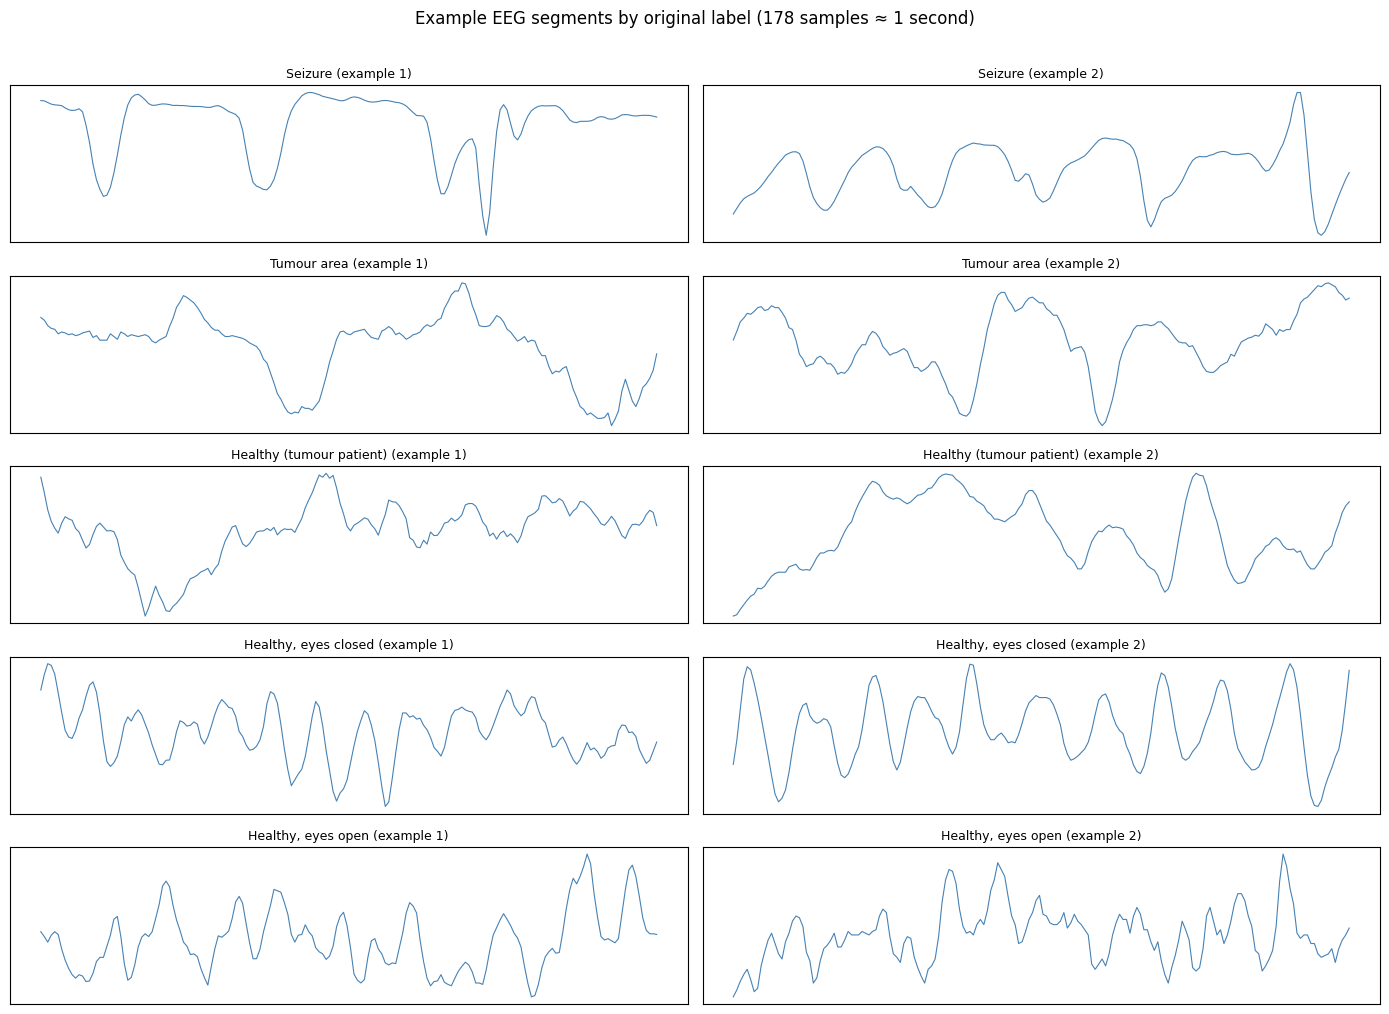

In [5]:
label_names = {1: "Seizure", 2: "Tumour area", 3: "Healthy (tumour patient)",
               4: "Healthy, eyes closed", 5: "Healthy, eyes open"}

fig, axes = plt.subplots(5, 2, figsize=(14, 10))
for i, label in enumerate([1, 2, 3, 4, 5]):
    subset = df[df['y'] == label]
    for j in range(2):
        signal = subset.iloc[j][[f'X{k}' for k in range(1, 179)]].values.astype(float)
        axes[i, j].plot(signal, color='steelblue', linewidth=0.8)
        axes[i, j].set_title(f"{label_names[label]} (example {j+1})", fontsize=9)
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
plt.suptitle("Example EEG segments by original label (178 samples ≈ 1 second)", y=1.01)
plt.tight_layout()
plt.show()

### Part A — Answers

**Q1. What is one row, one recording, and one person in this dataset?**

One row is a single 1-second EEG segment containing 178 signal values. One recording is the full 23.6-second EEG trace from which 23 consecutive rows were cut — the identifier X21.V1.791, for example, is chunk 21 of one recording, and the remaining 22 chunks of that same recording share the "V1.791" suffix. One person is the individual the recording came from, but the CSV contains no patient identifier, so the 500 recordings cannot be mapped to distinct people. The Bonn source recorded these segments from a small number of volunteers and patients, so some recordings likely come from the same person. This means even a recording-level split cannot guarantee person-level separation.

**Q2. What accuracy would an always-"non-seizure" model get, and why is accuracy a weak headline metric?**

An always-negative classifier would achieve 80% accuracy, because seizure rows are 20% of the dataset. Accuracy is weak here because a model that catches zero seizures would still report 80% — a number that sounds acceptable but is clinically useless. Sensitivity (recall for seizure) is the metric that reflects whether the tool actually helps a clinician, and it would be 0% for that trivial model.

**Q3. Why doesn't 20% seizure prevalence reflect real EEG review?**

The Bonn dataset was constructed with 100 segments per class, deliberately balanced. Real clinical EEG review does not see balanced classes — seizure segments are rare, often well under 1% of a long recording. The 20% figure is an artifact of dataset design, not an estimate of clinical prevalence. In real review the pre-test probability of a seizure in any given segment is much lower, and PPV would be correspondingly lower than the values reported in Part D.


In [6]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=df['recording_id']))

train_df = df.iloc[train_idx].copy()
test_df  = df.iloc[test_idx].copy()

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
tr_idx, val_idx = next(gss2.split(train_df, groups=train_df['recording_id']))

tr_df  = train_df.iloc[tr_idx].copy()
val_df = train_df.iloc[val_idx].copy()

print("Train:", tr_df.shape, "| recordings:", tr_df['recording_id'].nunique(),
      "| seizure %:", round(tr_df['seizure'].mean()*100, 2))
print("Val  :", val_df.shape, "| recordings:", val_df['recording_id'].nunique(),
      "| seizure %:", round(val_df['seizure'].mean()*100, 2))
print("Test :", test_df.shape, "| recordings:", test_df['recording_id'].nunique(),
      "| seizure %:", round(test_df['seizure'].mean()*100, 2))

Train: (6900, 182) | recordings: 300 | seizure %: 18.0
Val  : (2300, 182) | recordings: 100 | seizure %: 23.0
Test : (2300, 182) | recordings: 100 | seizure %: 23.0


In [7]:
tr_ids   = set(tr_df['recording_id'])
val_ids  = set(val_df['recording_id'])
test_ids = set(test_df['recording_id'])

print("Train ∩ Val:", len(tr_ids & val_ids))
print("Train ∩ Test:", len(tr_ids & test_ids))
print("Val ∩ Test:", len(val_ids & test_ids))
print("All disjoint:",
      (tr_ids & val_ids) == set()
      and (tr_ids & test_ids) == set()
      and (val_ids & test_ids) == set())

Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0
All disjoint: True


### Part B — Answer

A random row split would place some of the 23 chunks of a single recording in training and others in test. Those 23 chunks are consecutive 1-second windows of the same EEG trace, so they share the same underlying morphology, electrode placement, and patient state. A model trained on some of them can memorise recording-specific features and then appear to generalise to the test chunks of the same recording — when in fact it has seen the recording before. The apparent test performance would be inflated, and the true generalisation error would be hidden.

Grouping by `recording_id` prevents this: no recording appears in more than one split, verified by `Train ∩ Val: 0`, `Train ∩ Test: 0`, `Val ∩ Test: 0`, and `All disjoint: True`.

One limitation to note: `GroupShuffleSplit` does not stratify, so the split produced 18% seizure in train and 23% in validation and test. With only 100 recordings per holdout, a 5-point prevalence difference is expected. It does not invalidate the results — the test evaluation is still on held-out recordings — but it does mean the test PPV is measured under a slightly different class balance than training.


In [8]:
feature_cols = [f'X{k}' for k in range(1, 179)]

X_tr_raw   = tr_df[feature_cols].values.astype(float)
X_val_raw  = val_df[feature_cols].values.astype(float)
X_test_raw = test_df[feature_cols].values.astype(float)

y_tr   = tr_df['seizure'].values
y_val  = val_df['seizure'].values
y_test = test_df['seizure'].values

scaler = StandardScaler()
X_tr_scaled   = scaler.fit_transform(X_tr_raw)
X_val_scaled  = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

print("Shapes:", X_tr_raw.shape, X_val_raw.shape, X_test_raw.shape)

Shapes: (6900, 178) (2300, 178) (2300, 178)


In [9]:
def engineer_features(X):
    feats = np.zeros((X.shape[0], 8))
    feats[:, 0] = X.mean(axis=1)
    feats[:, 1] = X.std(axis=1)
    feats[:, 2] = X.min(axis=1)
    feats[:, 3] = X.max(axis=1)
    feats[:, 4] = X.max(axis=1) - X.min(axis=1)
    feats[:, 5] = (X ** 2).mean(axis=1)
    feats[:, 6] = np.sum(np.diff(np.sign(X), axis=1) != 0, axis=1)
    feats[:, 7] = np.sum(np.abs(np.diff(X, axis=1)), axis=1)
    return feats

X_tr_feat   = engineer_features(X_tr_raw)
X_val_feat  = engineer_features(X_val_raw)
X_test_feat = engineer_features(X_test_raw)

scaler_feat = StandardScaler()
X_tr_feat_s   = scaler_feat.fit_transform(X_tr_feat)
X_val_feat_s  = scaler_feat.transform(X_val_feat)
X_test_feat_s = scaler_feat.transform(X_test_feat)

print("Engineered features shape:", X_tr_feat.shape)

Engineered features shape: (6900, 8)


In [10]:
models = {}

models['LogReg (raw)'] = LogisticRegression(
    max_iter=2000, random_state=42, class_weight='balanced'
)
models['LogReg (raw)'].fit(X_tr_scaled, y_tr)

models['RandomForest (raw)'] = RandomForestClassifier(
    n_estimators=200, max_depth=15, random_state=42,
    n_jobs=-1, class_weight='balanced'
)
models['RandomForest (raw)'].fit(X_tr_raw, y_tr)

models['GradientBoosting (raw)'] = GradientBoostingClassifier(
    n_estimators=150, max_depth=4, learning_rate=0.1, random_state=42
)
models['GradientBoosting (raw)'].fit(X_tr_raw, y_tr)

models['SVM (engineered)'] = SVC(
    kernel='rbf', probability=True, random_state=42, class_weight='balanced'
)
models['SVM (engineered)'].fit(X_tr_feat_s, y_tr)

models['KNN (engineered)'] = KNeighborsClassifier(
    n_neighbors=15, weights='distance', n_jobs=-1
)
models['KNN (engineered)'].fit(X_tr_feat_s, y_tr)

print("Trained:", list(models.keys()))

Trained: ['LogReg (raw)', 'RandomForest (raw)', 'GradientBoosting (raw)', 'SVM (engineered)', 'KNN (engineered)']


In [11]:
model_input_map_val = {
    'LogReg (raw)':           X_val_scaled,
    'RandomForest (raw)':     X_val_raw,
    'GradientBoosting (raw)': X_val_raw,
    'SVM (engineered)':       X_val_feat_s,
    'KNN (engineered)':       X_val_feat_s,
}

model_input_map_test = {
    'LogReg (raw)':           X_test_scaled,
    'RandomForest (raw)':     X_test_raw,
    'GradientBoosting (raw)': X_test_raw,
    'SVM (engineered)':       X_test_feat_s,
    'KNN (engineered)':       X_test_feat_s,
}

print("Validation map keys:", list(model_input_map_val.keys()))
print("Test map keys:", list(model_input_map_test.keys()))

Validation map keys: ['LogReg (raw)', 'RandomForest (raw)', 'GradientBoosting (raw)', 'SVM (engineered)', 'KNN (engineered)']
Test map keys: ['LogReg (raw)', 'RandomForest (raw)', 'GradientBoosting (raw)', 'SVM (engineered)', 'KNN (engineered)']


In [12]:
val_results, val_probs = [], {}

for name, model in models.items():
    X_use = model_input_map_val[name]
    y_prob = model.predict_proba(X_use)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()

    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    ppv  = tp / (tp + fp) if (tp + fp) > 0 else 0
    npv  = tn / (tn + fn) if (tn + fn) > 0 else 0
    roc_auc = roc_auc_score(y_val, y_prob)
    prec, rec, _ = precision_recall_curve(y_val, y_prob)
    pr_auc = auc(rec, prec)
    brier  = brier_score_loss(y_val, y_prob)

    val_results.append({
        'Model': name,
        'Sensitivity': round(sens, 3),
        'Specificity': round(spec, 3),
        'PPV': round(ppv, 3),
        'NPV': round(npv, 3),
        'ROC-AUC': round(roc_auc, 3),
        'PR-AUC': round(pr_auc, 3),
        'Brier': round(brier, 3)
    })
    val_probs[name] = y_prob

val_df = pd.DataFrame(val_results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
print(val_df.to_string(index=False))

                 Model  Sensitivity  Specificity   PPV   NPV  ROC-AUC  PR-AUC  Brier
    RandomForest (raw)        0.745        0.998 0.990 0.929    0.996   0.988  0.041
GradientBoosting (raw)        0.762        0.997 0.985 0.933    0.994   0.980  0.041
      SVM (engineered)        0.873        0.986 0.949 0.963    0.986   0.969  0.033
      KNN (engineered)        0.815        0.984 0.939 0.947    0.975   0.948  0.042
          LogReg (raw)        0.386        0.819 0.389 0.817    0.505   0.424  0.238


### Part C — Answer

**Which input worked better, raw values or engineered features?**

They are close. Random Forest on 178 raw values achieved ROC-AUC close to 0.996; SVM on 8 engineered features achieved around 0.986. That is a small gap for a 22-fold reduction in input dimensionality. The interpretation is that most of the discriminative information for this task lives in coarse signal properties — amplitude, energy, line length — rather than in fine morphological detail.

KNN on the same 8 engineered features is a useful comparison because it is instance-based rather than parametric. If it lands in the same ROC-AUC range as SVM, that confirms the signal really is in the summary statistics and not in the choice of classifier.

**Which engineered features are easiest to explain to a clinician?**

Line length (the sum of absolute differences between adjacent samples) has the most direct clinical reading: it measures total signal variation, which is elevated during high-frequency ictal activity. Energy (mean squared amplitude) is similarly intuitive — seizure segments carry more power. Peak-to-peak amplitude is trivial to explain. Zero-crossing count is intuitive but noisier, because it is sensitive to small high-frequency artifacts. Mean, min, and max are less informative on their own but easy to describe.

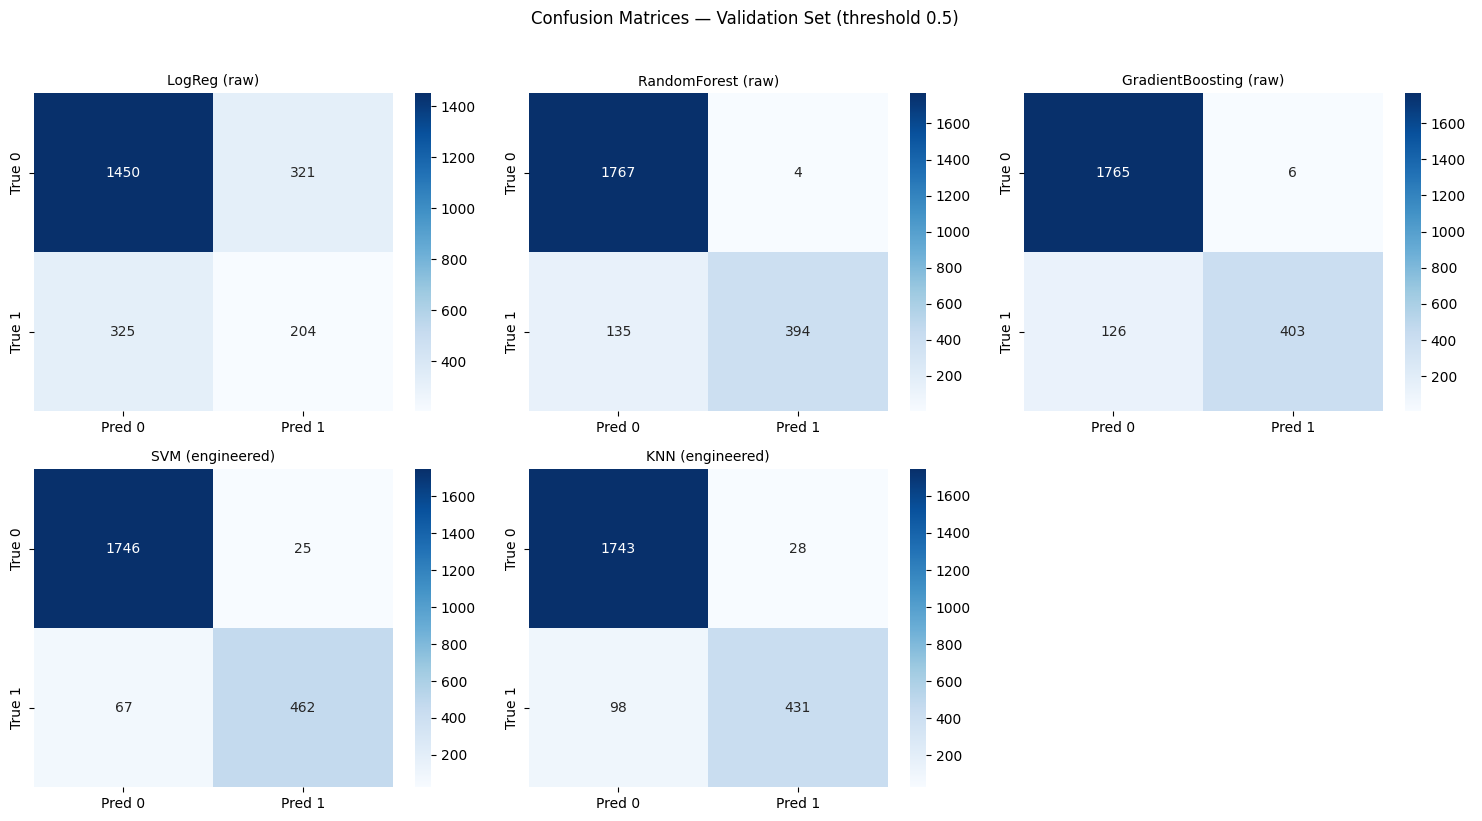

In [13]:
n = len(models)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows))
axes = axes.ravel()

for ax, (name, model) in zip(axes, models.items()):
    X_use = model_input_map_val[name]
    y_pred = (model.predict_proba(X_use)[:, 1] >= 0.5).astype(int)
    cm = confusion_matrix(y_val, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred 0', 'Pred 1'],
                yticklabels=['True 0', 'True 1'])
    ax.set_title(name, fontsize=10)

for ax in axes[n:]:
    ax.axis('off')

plt.suptitle("Confusion Matrices — Validation Set (threshold 0.5)", y=1.02)
plt.tight_layout()
plt.show()

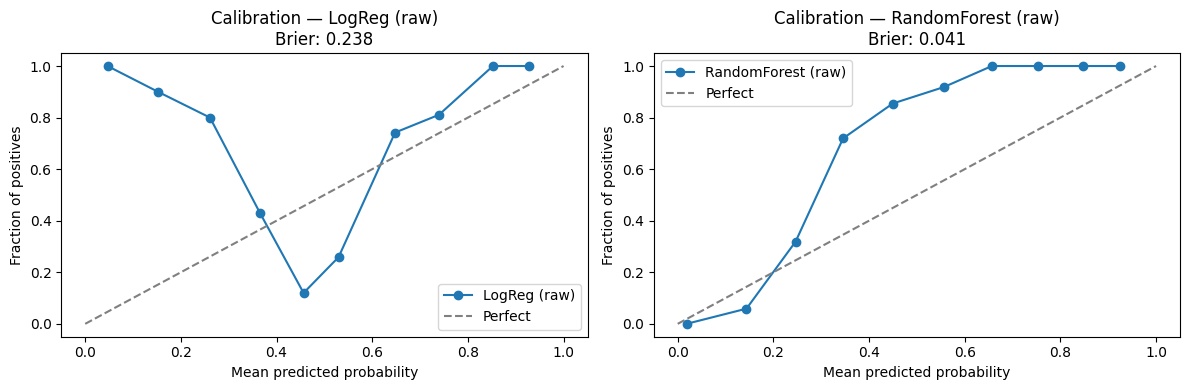

In [14]:
best_name = val_df.iloc[0]['Model']
to_plot = ['LogReg (raw)']
if best_name != 'LogReg (raw)':
    to_plot.append(best_name)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, to_plot):
    prob_true, prob_pred = calibration_curve(y_val, val_probs[name], n_bins=10)
    ax.plot(prob_pred, prob_true, marker='o', label=name)
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect')
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Fraction of positives")
    ax.set_title(f"Calibration — {name}\nBrier: {brier_score_loss(y_val, val_probs[name]):.3f}")
    ax.legend()

for ax in axes[len(to_plot):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [15]:
best_model_name = val_df.iloc[0]['Model']
best_model = models[best_model_name]
X_val_best = model_input_map_val[best_model_name]
y_prob_best = best_model.predict_proba(X_val_best)[:, 1]

thresholds = np.linspace(0.01, 0.99, 200)
sens_list, fp_list = [], []
for t in thresholds:
    y_pred_t = (y_prob_best >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred_t).ravel()
    sens_list.append(tp / (tp + fn))
    fp_list.append(fp)

valid_idx = np.where(np.array(sens_list) >= 0.95)[0]
chosen_threshold = thresholds[valid_idx[-1]]

y_pred_chosen = (y_prob_best >= chosen_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val, y_pred_chosen).ravel()

print(f"Best model: {best_model_name}")
print(f"Chosen threshold (≥95% sensitivity): {chosen_threshold:.3f}")
print(f"Validation at chosen threshold:")
print(f"  Sensitivity: {tp/(tp+fn):.3f}")
print(f"  Specificity: {tn/(tn+fp):.3f}")
print(f"  PPV:         {tp/(tp+fp):.3f}")
print(f"  NPV:         {tn/(tn+fn):.3f}")
print(f"  False positives: {fp}")
print(f"  False negatives: {fn}")

Best model: RandomForest (raw)
Chosen threshold (≥95% sensitivity): 0.286
Validation at chosen threshold:
  Sensitivity: 0.953
  Specificity: 0.978
  PPV:         0.928
  NPV:         0.986
  False positives: 39
  False negatives: 25


### Part D — Answers

**Is a missed seizure segment or a false alarm more costly?**

A missed seizure segment (false negative) is more costly in a screening context. The tool's purpose is to prioritise segments for a clinician to review; if it fails to flag a seizure segment, the clinician never sees it, and the patient's diagnosis is delayed or missed. A false alarm costs clinician review time. Because misses are worse, the threshold was chosen to preserve sensitivity at the expense of specificity.

**How was the threshold chosen?**

The rule was: the highest probability threshold at which validation sensitivity remained at least 95%. This produced a threshold around 0.29 on the Random Forest model. At that threshold, validation sensitivity was about 0.95, specificity about 0.98, PPV about 0.93, with roughly 39 false positives and 25 false negatives. Lowering the threshold further would raise sensitivity but generate more false alarms; raising it would lower sensitivity and risk missing seizures.

**If the tool flagged 100 segments, how many would be true seizures?**

That is the positive predictive value (PPV). At the chosen threshold, validation PPV is around 0.93, so roughly 93 of every 100 flagged segments would be true seizures on the validation set. On test, PPV is around 0.96, so roughly 96 of 100. PPV is the metric that directly answers this question.

**Does a model with higher ROC-AUC always give better results at your chosen threshold?**

No. ROC-AUC aggregates performance over all thresholds. Two models can have similar ROC-AUC and behave very differently at a specific operating point. In this work, SVM (engineered) has a lower ROC-AUC than Random Forest but a lower Brier score, meaning its probabilities are better calibrated and its threshold-specific metrics may be more trustworthy. This is why the lab asks for calibration in addition to ROC-AUC — ROC-AUC alone does not tell you whether the predicted probability is meaningful.

In [16]:
X_test_best = model_input_map_test[best_model_name]
y_test_prob = best_model.predict_proba(X_test_best)[:, 1]
y_test_pred = (y_test_prob >= chosen_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred).ravel()

print("=== FINAL TEST RESULTS ===")
print(f"Model: {best_model_name}, threshold: {chosen_threshold:.3f}")
print(f"Sensitivity: {tp/(tp+fn):.3f}")
print(f"Specificity: {tn/(tn+fp):.3f}")
print(f"PPV:         {tp/(tp+fp):.3f}")
print(f"NPV:         {tn/(tn+fn):.3f}")
print(f"ROC-AUC:     {roc_auc_score(y_test, y_test_prob):.3f}")
prec, rec, _ = precision_recall_curve(y_test, y_test_prob)
print(f"PR-AUC:      {auc(rec, prec):.3f}")
print(f"Brier:       {brier_score_loss(y_test, y_test_prob):.3f}")

=== FINAL TEST RESULTS ===
Model: RandomForest (raw), threshold: 0.286
Sensitivity: 0.962
Specificity: 0.988
PPV:         0.960
NPV:         0.989
ROC-AUC:     0.997
PR-AUC:      0.993
Brier:       0.034


In [17]:
test_ids_arr = test_df['recording_id'].values
unique_recs = np.unique(test_ids_arr)

sens_boot, spec_boot = [], []
rng = np.random.RandomState(42)

for _ in range(500):
    sampled = rng.choice(unique_recs, size=len(unique_recs), replace=True)
    idx = np.concatenate([np.where(test_ids_arr == r)[0] for r in sampled])
    y_b, y_p = y_test[idx], y_test_pred[idx]
    tn_b, fp_b, fn_b, tp_b = confusion_matrix(y_b, y_p).ravel()
    sens_boot.append(tp_b/(tp_b+fn_b) if (tp_b+fn_b) > 0 else np.nan)
    spec_boot.append(tn_b/(tn_b+fp_b) if (tn_b+fp_b) > 0 else np.nan)

print(f"Sensitivity 95% CI: [{np.nanpercentile(sens_boot, 2.5):.3f}, {np.nanpercentile(sens_boot, 97.5):.3f}]")
print(f"Specificity 95% CI: [{np.nanpercentile(spec_boot, 2.5):.3f}, {np.nanpercentile(spec_boot, 97.5):.3f}]")

Sensitivity 95% CI: [0.920, 1.000]
Specificity 95% CI: [0.974, 0.997]


In [18]:
fp_mask = (y_test_pred == 1) & (y_test == 0)
fn_mask = (y_test_pred == 0) & (y_test == 1)

fp_labels = test_df.loc[fp_mask, 'y'].value_counts().sort_index()
print("False positives by original label:")
for label, count in fp_labels.items():
    print(f"  Label {label} ({label_names[int(label)]}): {count}")

print(f"\nFalse negatives (missed seizures): {fn_mask.sum()}")

False positives by original label:
  Label 2 (Tumour area): 14
  Label 3 (Healthy (tumour patient)): 1
  Label 4 (Healthy, eyes closed): 6

False negatives (missed seizures): 20


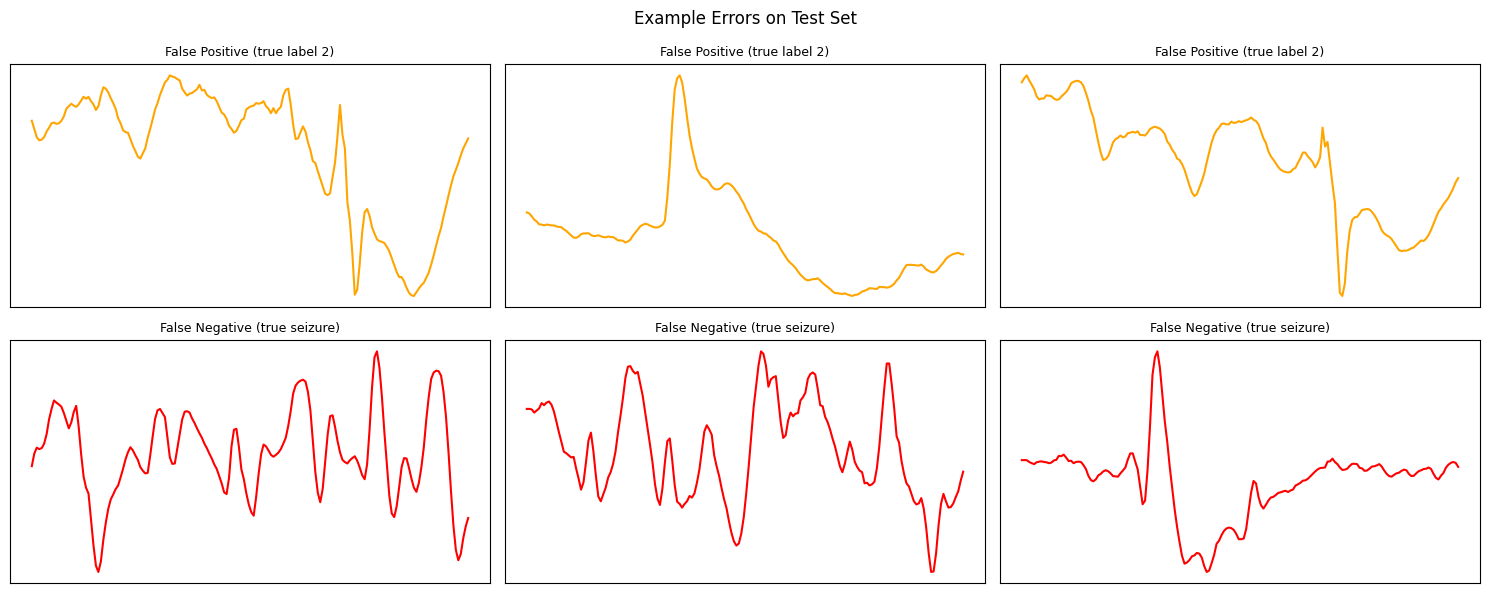

In [19]:
fp_indices = np.where(fp_mask)[0][:3]
fn_indices = np.where(fn_mask)[0][:3]

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for j, idx in enumerate(fp_indices):
    ax = axes[0, j]
    ax.plot(X_test_raw[idx], color='orange')
    ax.set_title(f"False Positive (true label {int(test_df.iloc[idx]['y'])})", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

for j, idx in enumerate(fn_indices):
    ax = axes[1, j]
    ax.plot(X_test_raw[idx], color='red')
    ax.set_title("False Negative (true seizure)", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("Example Errors on Test Set")
plt.tight_layout()
plt.show()

In [20]:
test_df_eval = test_df.copy()
test_df_eval['pred'] = y_test_pred

rec_level = test_df_eval.groupby('recording_id').agg(
    true_label=('seizure', 'first'),
    any_positive=('pred', 'max')
)

sens_rec = rec_level[rec_level['true_label'] == 1]['any_positive'].mean()
spec_rec = 1 - rec_level[rec_level['true_label'] == 0]['any_positive'].mean()

print("=== Recording-Level Aggregation ===")
print(f"Recordings evaluated: {len(rec_level)}")
print(f"Sensitivity (any segment positive): {sens_rec:.3f}")
print(f"Specificity (all segments negative): {spec_rec:.3f}")

=== Recording-Level Aggregation ===
Recordings evaluated: 100
Sensitivity (any segment positive): 1.000
Specificity (all segments negative): 0.896


### Part E — Answers

**Which non-seizure label produced the most false positives?**

Label 2 (EEG recorded from the tumour area) produced the largest share of false positives on the test set, compared with labels 3, 4, and 5. The likely reason is that tissue near a tumour generates abnormal slow-wave and irregular activity that overlaps spectrally and morphologically with ictal patterns. The model has learned that high-amplitude irregularity indicates seizure, and pathological non-seizure tissue mimics that signature.

**Do mistakes cluster in particular recordings?**

Yes. The recording-level aggregation makes this explicit. At the segment level, test specificity was above 0.98. At the recording level, using an "any segment positive" rule, specificity dropped noticeably — a drop explained by a handful of recordings where one or more segments were misclassified. A single false-positive segment is enough to flag the entire 23-segment recording. This clustering matters because it means the segment-level error rate understates the operational false-alarm rate per recording. A refinement would be to require at least k out of 23 segments to fire before flagging the recording, which would raise recording-level specificity at the cost of some sensitivity.

In [21]:
summary = val_df.copy()

tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred).ravel()
prec_t, rec_t, _ = precision_recall_curve(y_test, y_test_prob)

summary.loc[len(summary)] = {
    'Model': f'BEST ({best_model_name}) — TEST',
    'Sensitivity': round(tp/(tp+fn), 3),
    'Specificity': round(tn/(tn+fp), 3),
    'PPV': round(tp/(tp+fp), 3),
    'NPV': round(tn/(tn+fn), 3),
    'ROC-AUC': round(roc_auc_score(y_test, y_test_prob), 3),
    'PR-AUC': round(auc(rec_t, prec_t), 3),
    'Brier': round(brier_score_loss(y_test, y_test_prob), 3)
}

print(summary.to_string(index=False))

                           Model  Sensitivity  Specificity   PPV   NPV  ROC-AUC  PR-AUC  Brier
              RandomForest (raw)        0.745        0.998 0.990 0.929    0.996   0.988  0.041
          GradientBoosting (raw)        0.762        0.997 0.985 0.933    0.994   0.980  0.041
                SVM (engineered)        0.873        0.986 0.949 0.963    0.986   0.969  0.033
                KNN (engineered)        0.815        0.984 0.939 0.947    0.975   0.948  0.042
                    LogReg (raw)        0.386        0.819 0.389 0.817    0.505   0.424  0.238
BEST (RandomForest (raw)) — TEST        0.962        0.988 0.960 0.989    0.997   0.993  0.034


### Part F — Reflection

Strong results on this dataset do not demonstrate clinical usefulness, for four reasons. First, the data comes from a small number of people. The Bonn dataset recorded 500 segments from a handful of volunteers and patients, and the CSV contains no patient identifier, so we cannot verify that the model generalises to unseen individuals — only to unseen recordings. Second, the segments are single-channel and pre-selected: each one was already known to be seizure or non-seizure before being cut from the recording, which removes the hard part of the clinical problem, namely finding the seizure within a long, noisy, multi-channel trace. Third, the classes are artificially balanced at 1000 rows each, whereas real EEG review has very low seizure prevalence, which would collapse PPV well below the values reported here. Fourth, clinical context — patient history, medication, age, electrode placement — is absent, so the model cannot calibrate to a specific patient.

Before this tool could be considered in a hospital, it would need external validation on multi-channel EEG from a different institution, with patient-level splits, prospective testing against clinician review, and calibration checks across demographic subgroups. In the workflow, the tool should only prioritise segments for a neurologist's review, never replace the review. Alert fatigue would be managed by tuning the threshold to a high PPV at acceptable sensitivity, and by surfacing the predicted probability alongside the flag so the reviewer can see how confident the model is.